# Past-only GAM + spatiotemporal kriging — TS=2·4·6

**사건:** `US_2021_NM3323810847220210520`. 기존 노트북은 보존합니다.

이번 실험은 고정된 공간 평활항을 GAM에 넣는 실험이 아닙니다. **GAM을 기본 예측으로 고정하고, 과거 관측에 조건부인 잠재 오차 효과를 공분산 기반 시공간 크리깅으로 다음 날에 예측**합니다.

- 비교: GAM / GAM+STK × TS=2·4·6, 공통 target 날짜·픽셀.
- binary target: 다음 날 **새로 기록된** 누적 AF-or-BA 영역. 최초 발화나 순수 BA 증가가 아닙니다.
- 이항 우도 + 잠재 Gaussian process + Laplace 근사를 사용한 **generalized kriging**입니다. 연속형 농도에 적용하는 원시 잔차 ordinary kriging과 구분합니다.
- 사후 관측 실험. 원천 제품의 실제 공개 시각·합성 과정은 확정되지 않아 운영 예측 누수까지 검증됐다고 주장하지 않습니다.
- `DEMO_MODE=False` 기본. 실제 파일이 없으면 오류로 멈춥니다.

## 1. 설정 — 이 셀은 Bash가 아닌 Python입니다
README_HPC.md의 패키지 설치 후 **TS-SatFire GAM** 커널을 선택하세요. `BUNDLE_DIR`는 `st_kriging.py`가 있는 폴더입니다. 스레드 수는 배정된 HPC CPU 수 이하로 지정합니다. 기존 실행 결과는 매번 다른 UTC 폴더에 보존됩니다.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

BUNDLE_DIR = Path.cwd()
# HPC에서 필요하면 다음으로 변경:
# BUNDLE_DIR = Path("/mnt/pixstor/data/jlc3q/SatFire/TS-SatFire/notebooks/gam_st_kriging")
assert (BUNDLE_DIR / "st_kriging.py").exists(), "BUNDLE_DIR를 helper 폴더로 지정하세요."
sys.path.insert(0, str(BUNDLE_DIR))
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits
threadpool_limits(limits=int(os.environ.get("OMP_NUM_THREADS", "4")))
import st_kriging as sk

DEMO_MODE = True
CFG = sk.defaults()
CFG["raw_root"] = os.environ.get("TS_SATFIRE_RAW_ROOT", "/home/jlc3q/data/SatFire/ts-satfire")
CFG["event_id"] = "US_2021_NM3323810847220210520"
# 실제 데이터 구조가 바뀌면 실행 전에 확인할 것. 기존 사건 감사의 라벨 정책 유지.
CFG["label_nan_policy"] = "legacy_nan_zero"
CFG["timing_note"] = "사후 기록 화재 확산 실험. 데이터 공개시각 미검증; 운영 예측 성능으로 해석하지 않음."
# 크리깅의 잠재 효과 격자와 시간 범위; 시험 결과를 보고 바꾸지 않습니다.
CFG["block_pixels"] = 64
CFG["history_days"] = 3
CFG["spatial_ranges_km"] = [5.0, 20.0]
CFG["temporal_ranges_days"] = [1.0, 3.0]
CFG["correction_strengths"] = [0.0, 0.5, 1.0]

if DEMO_MODE:
    from satfire_demo import make_demo
    CFG.update(raw_root=str(BUNDLE_DIR / "demo_data"), event_id="SYNTHETIC_ONLY",
               features=["ndvi", "i4", "tmax"], negative_keep=1.,
               lambdas=[0.001, 0.01], n_knots=3, max_iter=2000,
               block_pixels=7, history_days=2,
               spatial_ranges_km=[3.], temporal_ranges_days=[1., 3.])
    make_demo(CFG["raw_root"], CFG["event_id"])
OUT = BUNDLE_DIR / "runs" / (("demo_" if DEMO_MODE else "real_") + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
print("SYNTHETIC ONLY" if DEMO_MODE else "RETROSPECTIVE REAL EVENT")
print("Source:", Path(CFG["raw_root"]) / CFG["event_id"])
print("Output:", OUT)

SYNTHETIC ONLY
Source: /private/tmp/satfire_stk_notebook_check/demo_data/SYNTHETIC_ONLY
Output: /private/tmp/satfire_stk_notebook_check/runs/demo_20261120T191441641986Z


## 2. 자료 감사와 공통 평가 manifest
기존 실험과 같은 50% / 25% / 나머지의 날짜 블록을 사용합니다. 가장 긴 TS=6 입력이 블록 안에 들어가는 날짜만 모든 모델에 공통으로 평가합니다.

38일 자료에서는 train target 2021-05-23–06-04 (13일), validation 06-11–06-13 (3일), test 06-20–06-23 (4일)입니다. 픽셀 정의는 전날까지 미기록 화재이면서 이전/현재 라벨 상태를 아는 픽셀입니다. Predictor 결측으로 평가 픽셀을 제거하지 않습니다.

`legacy_nan_zero`는 AF/BA의 NaN을 **양성 기록 없음**으로 해석하는 기존 가정입니다. 실제 무화재를 확인했다는 뜻이 아닙니다. 파일 누락·중복·격자 불일치·날짜 공백은 중단합니다. GDAL scale/offset만 사용하며 NDVI 배율을 추측하지 않습니다. Nodata는 구름 QA 마스크가 아닙니다.

In [2]:
data = sk.prepare(CFG, OUT)
display(data["manifest"])
display(data["manifest"].groupby("split", sort=False).agg(
    days=("target_date", "size"), first_target=("target_date", "min"), last_target=("target_date", "max"),
    pixels=("n", "sum"), positives=("positives", "sum")))
display(pd.read_csv(OUT / "inventory.csv").groupby(["product", "band"]).agg(
    finite_fraction_min=("finite_fraction", "min"), value_min=("minimum", "min"), value_max=("maximum", "max")))
print("Latent spatial cells per day:", len(data["centres"]))

,split,target_date,input_start_TS6,last_input,n,positives,pixel_sha256
0,train,2021-05-07,2021-05-01,2021-05-06,670,0,15e1bfa1a50cfa4c955866162232afc79fa207e2571f4c...
1,train,2021-05-08,2021-05-02,2021-05-07,670,19,15e1bfa1a50cfa4c955866162232afc79fa207e2571f4c...
2,train,2021-05-09,2021-05-03,2021-05-08,651,0,8259def8168645f10e8450535e1248d50f47abc627641f...
3,train,2021-05-10,2021-05-04,2021-05-09,651,19,8259def8168645f10e8450535e1248d50f47abc627641f...
4,train,2021-05-11,2021-05-05,2021-05-10,632,0,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
5,train,2021-05-12,2021-05-06,2021-05-11,632,0,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
6,train,2021-05-13,2021-05-07,2021-05-12,632,19,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
7,train,2021-05-14,2021-05-08,2021-05-13,613,0,c5a6c9b405a973db2c62e30595ac1703d9309043e1403c...
8,train,2021-05-15,2021-05-09,2021-05-14,613,19,c5a6c9b405a973db2c62e30595ac1703d9309043e1403c...
9,train,2021-05-16,2021-05-10,2021-05-15,594,0,a87a9f1e66c303cdcbfb15fe666c55ee9af05eea473704...


,days,first_target,last_target,pixels,positives
split,,,,,
train,14,2021-05-07,2021-05-20,8658,114
val,4,2021-05-27,2021-05-30,1958,38
test,4,2021-06-06,2021-06-09,1616,38


finite_fraction_min   value_min  value_max
product   band                                            
FirePred  1                0.954082    0.239228    0.64886
          2                1.000000    0.239228    0.64886
          3                1.000000    0.239228    0.64886
          4                1.000000    0.239228    0.64886
          5                1.000000    0.239228    0.64886
          6                1.000000    0.239228    0.64886
          7                1.000000   20.000000   25.82000
          8                1.000000    0.239228    0.64886
          9                1.000000    0.239228    0.64886
          10               1.000000    0.239228    0.64886
          11               1.000000    0.239228    0.64886
          12               1.000000    0.239228    0.64886
          13               1.000000    0.239228    0.64886
          14               1.000000    0.239228    0.64886
          15               1.000000    0.239228    0.64886
          16               1.000000    0.239228    0.64886
          17               1.000000    0.239228    0.64886
          18               1.000000    0.239228    0.64886
          19               1.000000    0.239228    0.64886
VIIRS_Day 1                1.000000    0.239228    0.64886
          2                1.000000    0.239228    0.64886
          3                1.000000    0.239228    0.64886
          4                0.984694  290.000000  328.00000
          5                1.000000    0.239228    0.64886
          6                1.000000    0.239228    0.64886
          7                0.998724    0.000000    1.00000
          8                0.998724    0.000000    1.00000

Latent spatial cells per day: 16


## 3. 정확히 무엇을 크리깅하는가?
픽셀 $i$의 GAM 예측을 $p_i^G$, 고정 offset을 $\eta_i=\operatorname{logit}p_i^G$라 둡니다. 공간 블록 $b(i)$와 날짜 $d$에 잠재 효과 $f_{b,d}$를 둡니다.

\[
Y_{i,d}\mid f\sim\mathrm{Bernoulli}\{\operatorname{sigmoid}(\eta_{i,d}+f_{b(i),d})\},\quad f\sim N(0,K).
\]

\[
K((b,d),(b',d'))=\sigma^2\exp\{-\|s_b-s_{b'}\|/\ell_s-|d-d'|/\ell_t\}.
\]

$s_b$는 AEQD 좌표(km)의 블록 중심입니다. $\ell_s$, $\ell_t$는 e-folding 거리/시간이며 validation 후보 중 선택합니다. 잠재 분산 $\sigma^2=1$은 사전 고정하고, 최종 보정 강도 $\alpha$를 validation에서 선택합니다. 경험 variogram을 적합했다고 주장하지 않습니다.

**공간 근사:** 블록 안에서는 오차 효과가 일정하다고 가정하고 블록 중심 사이의 공분산을 사용합니다. 면적 적분으로 계산한 정확한 block kriging covariance는 아닙니다. 하지만 블록 내 픽셀마다 GAM offset은 다르고, 모든 관측 픽셀의 Bernoulli 우도를 그대로 합산합니다. 평균 확률을 하나의 binomial 확률로 대체하지 않습니다. 596×595 격자에서 64×64 블록이면 약 100개 잠재 위치이며, 3일 이력은 최대 약 300개 잠재 상태입니다.

Laplace/Newton 단계에서 과거 블록별 score와 정보량은
\[
g_b=\sum_{i\in b}(y_i-p_i),\quad W_b=\sum_{i\in b}p_i(1-p_i),\quad z_b=f_b+g_b/W_b.
\]
수렴 후 다음 날의 잠재 효과는 실제 크리깅 시스템으로 계산됩니다.
\[
\hat f_*=K_{*o}(K_{oo}+W^{-1})^{-1}z.
\]
구현은 역행렬을 직접 만들지 않고 안정적인 Cholesky 풀이를 사용합니다. 공간 RBF를 GAM 설명변수에 붙이는 방식과 다릅니다.

최종 확률은 Laplace 근사의 평균·분산에 대해 Gauss–Hermite 적분한
\[
\hat p_*=E[\operatorname{sigmoid}(\eta_*+\alpha F_*)\mid\text{과거 관측}]
\]
입니다. 확률에 잔차를 더해 잘라내지 않습니다. $\alpha=0$은 GAM과 정확히 같으며, validation에서 이 값이 선택되면 **크리깅의 추가 이득이 없었다고 보고**합니다. 조건부 잠재 표준편차는 진단용이며 GAM 계수·공분산 선택·라벨 오차를 포함하는 검증된 예측구간이 아닙니다.

## 4. 시간적 누수 방지 — GAM fit과 GP conditioning 구분
1. GAM 전처리·계수는 train에서만 적합합니다. 같은 학습 표본/가중치를 세 TS에서 사용합니다. 두 모델은 **완전히 같은 GAM**을 공유합니다.
2. GAM 학습 종료일 다음 날부터 과거 예측을 만들고 관측이 도착한 후 오차 정보를 구성합니다. train 안의 in-sample 잔차는 사용하지 않습니다. 실제 38일 자료에서는 06-05 이후가 가능하며, 첫 validation 예측(06-11)은 06-08–06-10의 과거 관측만 사용합니다.
3. 예측일 d의 GAM 입력은 d−1까지이고 GP 조건부 추정은 d−3…d−1만 봅니다. d의 라벨은 확률 생성이 끝난 뒤 평가 마스크·점수 계산에만 사용합니다.
4. GAM λ는 validation의 GAM log loss로 선택합니다. 동일 GAM에 공간·시간 범위와 보정 강도를 validation log loss로 선택하고, 각각의 F1 임계값도 validation에서 선택합니다.
5. 선택 결과를 저장·해시 고정한 뒤 test를 실행합니다. test에서 GAM을 다시 학습하거나 covariance/threshold를 조정하지 않습니다. 다만 과거 test일의 관측이 다음 날 GP conditioning에 들어가는 것은 **명시적으로 허용한 one-step rolling-origin 방식**입니다.

첫 test일 06-20의 GP는 06-17–06-19 관측을 사용합니다. 06-21에는 06-18–06-20 관측을 사용합니다. 따라서 train/validation/test의 **TS 입력+타겟 영상 블록은 분리**되지만, 과거 화재 상태와 과거 잔차 이력은 날짜 경계를 넘어 이어집니다. 시험 시작일에서 여러 날을 한 번에 예측하는 실험이 아닙니다.

기존 GAM은 과거 누적 화재를 설명변수로 사용하고, 새 결합모형은 추가로 최근 관측의 오차를 조건부 추정에 활용합니다. 두 모델이 오직 같은 고정 training label만 사용한다고 해석하지 마세요. 코드의 미래 접근 차단과 별개로 upstream 제품 자체의 과거 시점 가용성은 미검증입니다.

In [3]:
used = {}
for split, dates in data["targets"].items():
    used[split] = set()
    for d in dates:
        i = data["days"].index(d)
        used[split].update(data["days"][i-6:i+1])
assert not (used["train"] & used["val"] or used["train"] & used["test"] or used["val"] & used["test"])
for split in ["val", "test"]:
    d = data["days"].index(data["targets"][split][0])
    support = list(range(max(data["train_end"]+1, d-CFG["history_days"]), d))
    assert support and max(support) < d and min(support) > data["train_end"]
    print(split, "first forecast:", data["days"][d].date(), "past conditioning dates:", [str(data["days"][j].date()) for j in support])
print("Passed: disjoint scoring-window raster blocks; GP observations strictly past and out of GAM training.")

val first forecast: 2021-05-27 past conditioning dates: ['2021-05-25', '2021-05-26']
test first forecast: 2021-06-06 past conditioning dates: ['2021-06-04', '2021-06-05']
Passed: disjoint scoring-window raster blocks; GP observations strictly past and out of GAM training.


## 5. 학습과 validation 선택
기존 GAM과 같은 last/mean/change/missing-fraction 특징 및 화재 거리/주변 비율을 사용합니다. GAM 학습에서 양성은 전부, 음성은 5%를 추출하고 역포함확률 가중치를 줍니다. 반면 GP 우도는 이력 날짜의 **전체 유효 평가대상 픽셀**을 사용합니다.

실제 HPC 실행 시간/메모리는 아직 측정되지 않았습니다. CPU 4개/RAM 32GB를 시작점으로 고려하고 할당된 계산 노드에서 실행하세요. 후보 수렴 실패는 기록되며, 모든 kriging 후보가 실패하면 중단합니다. 크리깅 실패를 조용히 GAM으로 대체하지 않습니다.

In [4]:
selected = sk.train_select(data)
display(pd.read_csv(OUT / "gam_tuning.csv"))
display(pd.read_csv(OUT / "kriging_tuning.csv"))
display(pd.DataFrame(json.loads((OUT / "selection_before_test.json").read_text())))
display(pd.read_csv(OUT / "validation_conditioning_audit.csv").tail(12))

TS=2 GAM lambda=0.001


TS=2 GAM lambda=0.01


TS=2 latent ST kriging: spatial=3.0 km, temporal=1.0 d


TS=2 latent ST kriging: spatial=3.0 km, temporal=3.0 d


TS=4 GAM lambda=0.001


TS=4 GAM lambda=0.01


... (6 outputs left out)

,ts,lam,status,val_log_loss
0,2,0.001,converged,0.039823
1,2,0.010,converged,0.044461
2,4,0.001,converged,0.040019
3,4,0.010,converged,0.045185
4,6,0.001,converged,0.040099
5,6,0.010,converged,0.045183


,ts,space,time,strength,status,val_log_loss
0,2,NaN,NaN,0.0,GAM fallback,0.039823
1,2,3.0,1.0,0.5,converged,0.034843
2,2,3.0,1.0,1.0,converged,0.031632
3,2,3.0,3.0,0.5,converged,0.029602
4,2,3.0,3.0,1.0,converged,0.023639
5,4,NaN,NaN,0.0,GAM fallback,0.040019
6,4,3.0,1.0,0.5,converged,0.035151
7,4,3.0,1.0,1.0,converged,0.031980
8,4,3.0,3.0,0.5,converged,0.029968
9,4,3.0,3.0,1.0,converged,0.024073


,ts,gam_lambda,gam_threshold,gam_val_log_loss,kriging_space,kriging_time,strength,kriging_threshold,kriging_val_log_loss
0,2,0.001,0.615760,0.039823,3.0,3.0,1.0,0.619416,0.023639
1,4,0.001,0.611615,0.040019,3.0,3.0,1.0,0.590120,0.024073
2,6,0.001,0.633101,0.040099,3.0,3.0,1.0,0.632210,0.023921


,ts,target_day,target_date,spatial_range,temporal_range,nodes,observations,positives,iterations,gradient_max,objective,first_support_day,last_support_day
12,4,26,2021-05-27,3.0,3.0,24,1036,19,4,3.615359e-06,17.687577,24,25
13,4,27,2021-05-28,3.0,3.0,24,1017,19,4,7.024597e-06,18.285231,25,26
14,4,28,2021-05-29,3.0,3.0,24,998,19,4,9.570751e-06,20.057697,26,27
15,4,29,2021-05-30,3.0,3.0,24,979,19,5,3.132472e-11,20.828464,27,28
16,6,26,2021-05-27,3.0,1.0,24,1036,19,4,1.224522e-06,18.200699,24,25
17,6,27,2021-05-28,3.0,1.0,24,1017,19,4,2.540478e-06,18.926069,25,26
18,6,28,2021-05-29,3.0,1.0,24,998,19,4,2.978679e-06,21.426032,26,27
19,6,29,2021-05-30,3.0,1.0,24,979,19,4,7.487338e-06,22.215467,27,28
20,6,26,2021-05-27,3.0,3.0,24,1036,19,4,4.198257e-06,17.442659,24,25
21,6,27,2021-05-28,3.0,3.0,24,1017,19,4,7.873029e-06,18.072598,25,26


## 6. 고정된 선택으로 공통 test 평가
`GAM_STK`는 선택된 결합 파이프라인입니다. strength=0이면 no-correction 선택이므로 GAM과 같은 결과가 정상입니다. 실제 크리깅 후보의 validation 결과는 kriging_tuning.csv에 남습니다.

AP·Brier·log loss를 우선 확인하고 F1/IoU/precision/recall을 함께 봅니다. test 결과로 임계값을 다시 고르지 않습니다. 양성 없는 날도 제거하지 않습니다. 과거에 이미 확인한 같은 사건의 시험일이므로 이번 결과는 탐색적이며 새로운 사건의 독립 검증을 대체하지 않습니다.

In [5]:
metrics = sk.evaluate(data, selected)
display(metrics)
display(pd.read_csv(OUT / "paired_differences.csv"))
display(pd.read_csv(OUT / "test_metrics_by_date.csv"))
print("Constant baseline:", json.loads((OUT / "constant_baseline.json").read_text()))
audit_path = OUT / "test_conditioning_audit.csv"
if audit_path.stat().st_size > 1:
    audit = pd.read_csv(audit_path)
    assert (audit.last_support_day < audit.target_day).all()
    display(audit)
else:
    print("All selected strengths were zero; no test GP conditioning was needed.")

,ts,model,strength,threshold,n,positives,prevalence,ap,roc_auc,brier,log_loss,precision,recall,f1,iou
0,2,GAM,0.0,0.615760,1616,38,0.023515,0.223313,0.962111,0.026320,0.073063,0.095238,0.105263,0.100000,0.052632
1,2,GAM_STK,1.0,0.619416,1616,38,0.023515,0.494787,0.982289,0.015422,0.048181,0.500000,0.052632,0.095238,0.050000
2,4,GAM,0.0,0.611615,1616,38,0.023515,0.231623,0.963828,0.025457,0.070924,0.054054,0.052632,0.053333,0.027397
3,4,GAM_STK,1.0,0.590120,1616,38,0.023515,0.500260,0.982906,0.015356,0.048105,0.285714,0.052632,0.088889,0.046512
4,6,GAM,0.0,0.633101,1616,38,0.023515,0.217365,0.960693,0.027683,0.076671,0.086957,0.105263,0.095238,0.050000
5,6,GAM_STK,1.0,0.632210,1616,38,0.023515,0.453109,0.981222,0.015952,0.049573,0.500000,0.026316,0.050000,0.025641


,ts,delta_ap,delta_brier,delta_log_loss,delta_f1,delta_iou
0,2,0.271474,-0.010898,-0.024882,-0.004762,-0.002632
1,4,0.268638,-0.010101,-0.022819,0.035556,0.019114
2,6,0.235744,-0.011732,-0.027098,-0.045238,-0.024359


,ts,model,date,n,positives,prevalence,ap,roc_auc,brier,log_loss,precision,recall,f1,iou
0,2,GAM,2021-06-06,423,19,0.044917,0.392812,0.966780,0.030878,0.087615,0.285714,0.210526,0.242424,0.137931
1,2,GAM_STK,2021-06-06,423,19,0.044917,0.727103,0.985930,0.020452,0.063226,1.000000,0.105263,0.190476,0.105263
2,2,GAM,2021-06-07,404,0,0.000000,NaN,NaN,0.017576,0.048632,0.000000,0.000000,0.000000,0.000000
3,2,GAM_STK,2021-06-07,404,0,0.000000,NaN,NaN,0.007581,0.024859,0.000000,0.000000,0.000000,0.000000
4,2,GAM,2021-06-08,404,19,0.047030,0.330123,0.952973,0.036759,0.100693,0.000000,0.000000,0.000000,0.000000
5,2,GAM_STK,2021-06-08,404,19,0.047030,0.745448,0.981545,0.024564,0.074646,0.000000,0.000000,0.000000,0.000000
6,2,GAM,2021-06-09,385,0,0.000000,NaN,NaN,0.019533,0.053717,0.000000,0.000000,0.000000,0.000000
7,2,GAM_STK,2021-06-09,385,0,0.000000,NaN,NaN,0.008532,0.028353,0.000000,0.000000,0.000000,0.000000
8,4,GAM,2021-06-06,423,19,0.044917,0.459709,0.974075,0.027156,0.078167,0.222222,0.105263,0.142857,0.076923
9,4,GAM_STK,2021-06-06,423,19,0.044917,0.852677,0.990490,0.018964,0.059703,1.000000,0.105263,0.190476,0.105263


Constant baseline: {'train_prevalence': 0.013167013167013167, 'n': 1616, 'positives': 38, 'prevalence': 0.023514851485148515, 'ap': 0.023514851485148515, 'roc_auc': 0.5, 'brier': 0.023068981002638194, 'log_loss': 0.11476305113772227, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'iou': 0.0}


,ts,target_day,target_date,spatial_range,temporal_range,nodes,observations,positives,iterations,gradient_max,objective,first_support_day,last_support_day
0,2,36,2021-06-06,3.0,3.0,24,865,19,5,3.206301e-10,34.891560,34,35
1,2,37,2021-06-07,3.0,3.0,24,846,19,5,3.677720e-10,33.946019,35,36
2,2,38,2021-06-08,3.0,3.0,24,827,19,5,3.995044e-10,34.483432,36,37
3,2,39,2021-06-09,3.0,3.0,24,808,19,5,3.530360e-10,37.118458,37,38
4,4,36,2021-06-06,3.0,3.0,24,865,19,5,4.350418e-10,28.697793,34,35
5,4,37,2021-06-07,3.0,3.0,24,846,19,5,5.356937e-10,30.837477,35,36
6,4,38,2021-06-08,3.0,3.0,24,827,19,5,2.647498e-10,32.832397,36,37
7,4,39,2021-06-09,3.0,3.0,24,808,19,5,3.277054e-10,36.903034,37,38
8,6,36,2021-06-06,3.0,3.0,24,865,19,5,2.840407e-10,32.106219,34,35
9,6,37,2021-06-07,3.0,3.0,24,846,19,5,3.039319e-10,35.127935,35,36


Matplotlib is building the font cache; this may take a moment.


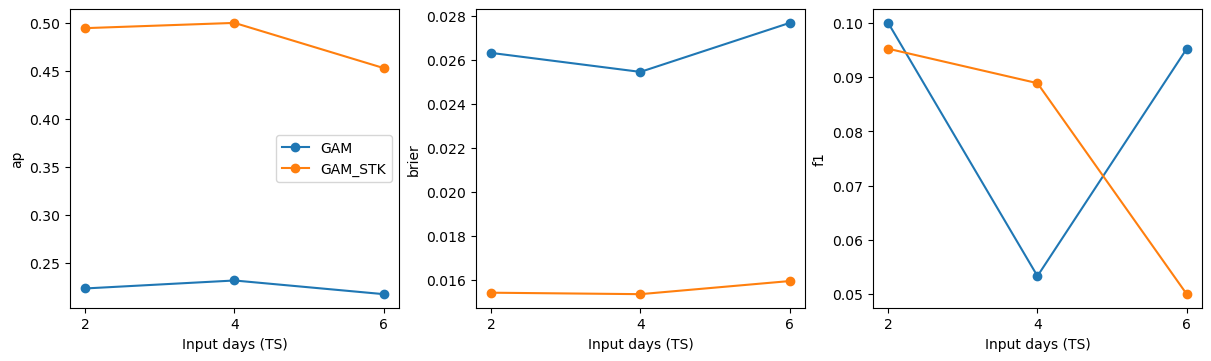

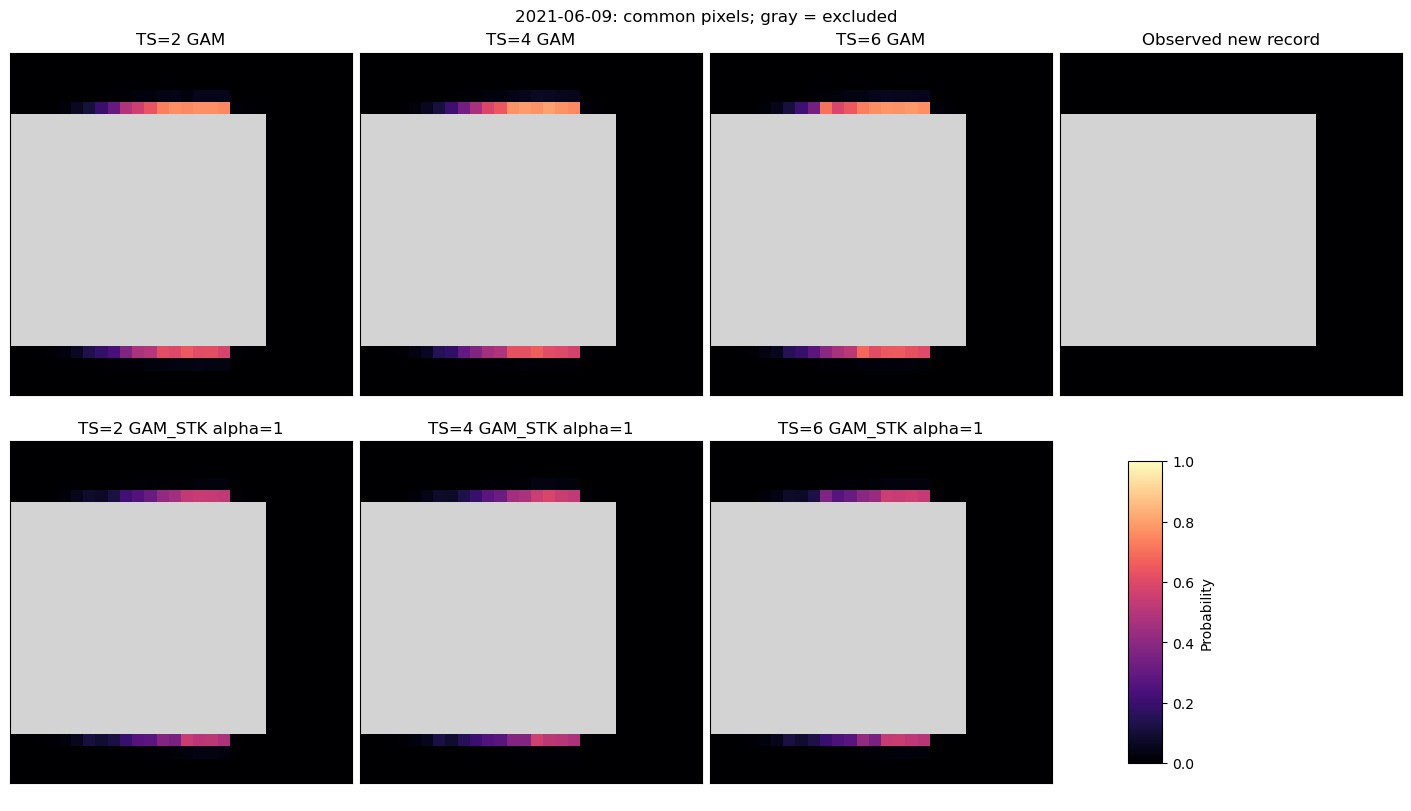

,ts,model,bin,n,mean_probability,observed_fraction
0,2,GAM,0,162,7.881080e-07,0.000000
1,2,GAM,1,161,2.808837e-06,0.000000
2,2,GAM,2,162,5.565178e-06,0.000000
3,2,GAM,3,161,1.107179e-05,0.000000
4,2,GAM,4,162,2.306366e-05,0.000000
5,2,GAM,5,162,4.983011e-05,0.000000
6,2,GAM,6,161,1.168554e-04,0.000000
7,2,GAM,7,161,5.533742e-04,0.000000
8,2,GAM,8,162,1.441211e-02,0.000000
9,2,GAM,9,162,4.365967e-01,0.234568


Saved: /private/tmp/satfire_stk_notebook_check/runs/demo_20261120T191441641986Z


In [6]:
sk.plots(data)
display(pd.read_csv(OUT / "calibration.csv"))
print("Saved:", OUT)

## 결과 파일과 해석
- `evaluation_manifest.csv`: 동일 target 날짜/픽셀 SHA256 및 양성 수.
- `training_rows.npz`: GAM 공통 학습 픽셀·날짜·가중치.
- `spatial_blocks.npz`: pixel→latent block, 실제 km 좌표. 블록 크기를 바꾸면 다른 실험입니다.
- `gam_tuning.csv`, `kriging_tuning.csv`, `selection_before_test.json`, `selection_seal.json`: 시험 전 선택 증거.
- `validation_conditioning_audit.csv`, `test_conditioning_audit.csv`: target와 support 날짜, 관측 수, 양성 수, Laplace 수렴 오차.
- `predictions/TS*_YYYY-MM-DD.npz`: 공통 ids/y, GAM 확률, GAM+STK 확률, 잠재 mean/sd, 선택 strength.
- `test_metrics.csv`, `test_metrics_by_date.csv`, `paired_differences.csv`, `calibration.csv`: 전체·날짜별 성능과 확률 보정.
- `base_predictions/`, `observations/`: 해당 실행 내부의 재사용 캐시. 다른 실행의 모델/설정 캐시를 복사해 섞지 마세요.

이 구현은 zero-mean latent GP의 covariance conditioning이며, 산불 이동 방향을 물리적으로 모사하지 않습니다. 공간 효과의 block 근사, separable exponential covariance, 고정된 prior variance와 짧은 이력은 모델 가정입니다. 개선이 없거나 검증에서 strength=0이 선택되는 것도 유효한 결과입니다.

방법 참고: [Rasmussen & Williams (2006), GPML, Chapter 3](https://gaussianprocess.org/gpml/chapters/RW.pdf), [Kuss & Rasmussen (2005), binary GP approximate inference](https://www.jmlr.org/papers/v6/kuss05a.html). 이 자료들은 Bernoulli likelihood와 Laplace inference의 근거이며 본 산불 파이프라인의 성능을 보장하지 않습니다. TS 비교의 데이터 맥락은 [TS-SatFire](https://arxiv.org/abs/2412.11555)입니다. 원 논문의 다사건 학습/공식 시험 성능 재현은 아닙니다.